# Baseline · Clasificación de quejas CFPB sin equilibrado

## 1. Entorno y configuración

In [1]:
from pathlib import Path
from textwrap import fill
import sys
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "cfpb_complaints_2023-06-01_2024-05-31").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("No se encuentra el CSV en su carpeta original dentro del proyecto.")
sys.path.insert(0, str(ROOT / "Baseline"))
from baseline import cargar_datos, crear_particiones, auditar_particiones, ejecutar_baseline, MODEL_NAME
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
configuration = {
    "Entrada del modelo": "Solo Consumer complaint narrative",
    "Objetivo": "Product armonizado: 11 categorías",
    "Normalización": "Minúsculas, espacios compactados y strip; misma función en ajuste e inferencia",
    "Partición": "Aleatoria por filas y estratificada por Product: 70/15/15; semilla 42",
    "Equilibrado": "No: class_weight=None, sin remuestreo ni sample_weight",
    "Duplicados": "Se conservan; se mide y publica el solapamiento entre particiones",
    "Referencia": "Clase más frecuente en entrenamiento",
    "Modelo": "TF-IDF palabras y bigramas + regresión logística multiclase",
    "Parámetros fijados antes de evaluar": "80.000 términos; min_df=3; C=1; max_iter=300; tol=0,001",
    "Métrica principal": "Macro-F1 sobre las 11 clases",
    "Métricas complementarias": "Accuracy, F1 ponderada, precisión/recall/F1 y soporte por clase",
    "Uso de validación": "Diagnóstico del baseline y selección futura de mejoras",
    "Uso de prueba": "Evaluación del baseline fijo; no ajustar hiperparámetros usando este conjunto",
    "Confianza": "Scores máximos sin calibrar; aún no hay umbral ni flag de revisión",
    "Salida": "Tablas y gráficas dentro del notebook; no se exportan resultados ni modelos",
}
display(pd.Series(configuration, name="Configuración").to_frame())

,Configuración
Entrada del modelo,Solo Consumer complaint narrative
Objetivo,Product armonizado: 11 categorías
Normalización,"Minúsculas, espacios compactados y strip; mism..."
Partición,Aleatoria por filas y estratificada por Produc...
Equilibrado,"No: class_weight=None, sin remuestreo ni sampl..."
Duplicados,Se conservan; se mide y publica el solapamient...
Referencia,Clase más frecuente en entrenamiento
Modelo,TF-IDF palabras y bigramas + regresión logísti...
Parámetros fijados antes de evaluar,80.000 términos; min_df=3; C=1; max_iter=300; ...
Métrica principal,Macro-F1 sobre las 11 clases


## 2. Lectura completa y reglas aprobadas

In [2]:
datos = cargar_datos(ROOT)
datos.head(2)

,Date received,Product,Sub-product,Consumer complaint narrative,Company,Complaint ID,normalized_hash,Product_original
0,2023-06-01,Credit reporting or other personal consumer re...,Credit reporting,On XX/XX/2023 I sent a letter regarding inaccu...,"EQUIFAX, INC.",7050835,17312234834978227486,"Credit reporting, credit repair services, or o..."
1,2023-06-01,Credit reporting or other personal consumer re...,Credit reporting,"To provide some context, I have thoroughly rev...","EQUIFAX, INC.",7050841,163840027774022237,"Credit reporting, credit repair services, or o..."


## 3. Particiones y diagnóstico de textos compartidos

In [3]:
particiones = crear_particiones(datos)
auditoria = auditar_particiones(datos, particiones)
display(auditoria["resumen"].round(2))
display(auditoria["soporte"])
display(auditoria["solapamiento"].round(5))

,Filas,% del corte,Clases,Textos distintos,Fecha mínima,Fecha máxima
Partición,,,,,,
Entrenamiento,407741,70.0,11,266428,2023-06-01,2024-05-31
Validación,87374,15.0,11,64464,2023-06-01,2024-05-31
Prueba,87374,15.0,11,64387,2023-06-01,2024-05-31


,Entrenamiento,Validación,Prueba
Product,,,
Credit reporting or other personal consumer reports,294854,63184,63184
Debt collection,34807,7459,7459
Credit card,26609,5702,5702
Checking or savings account,19070,4087,4086
Mortgage,8444,1810,1810
"Money transfer, virtual currency, or money service",6324,1355,1355
Student loan,5925,1269,1270
Vehicle loan or lease,5053,1083,1083
"Payday loan, title loan, personal loan, or advance loan",3279,702,702


,Partición,Referencia,Filas con texto compartido,% de filas con texto compartido,Textos distintos compartidos
0,Validación,Entrenamiento,36779,42.09376,14695
1,Prueba,Entrenamiento,36684,41.98503,14508
2,Prueba,Entrenamiento + validación,38281,43.81280,15934


## 4. Entrenamiento

In [4]:
resultado = ejecutar_baseline(datos, particiones)
display(pd.Series({
    "Modelo": MODEL_NAME, "Tiempo de entrenamiento (s)": round(resultado["entrenamiento_segundos"],2),
    "Vocabulario aprendido solo en entrenamiento": resultado["vocabulario"],
    "Iteraciones": resultado["iteraciones"],
    "Avisos del ajuste": " | ".join(resultado["avisos"]) or "Sin avisos",
    "Equilibrado aplicado": "No",
}, name="Ajuste").to_frame())

,Ajuste
Modelo,TF-IDF + regresión logística
Tiempo de entrenamiento (s),171.46
Vocabulario aprendido solo en entrenamiento,80000
Iteraciones,55
Avisos del ajuste,Sin avisos
Equilibrado aplicado,No


## 5. Comparación con la clase mayoritaria

,Modelo,Partición,Accuracy,Macro-F1,F1 ponderada
0,Clase mayoritaria,Validación,0.7231,0.0763,0.6070
1,TF-IDF + regresión logística,Validación,0.9012,0.6691,0.8966
2,Clase mayoritaria,Prueba,0.7231,0.0763,0.6070
3,TF-IDF + regresión logística,Prueba,0.9009,0.6683,0.8960


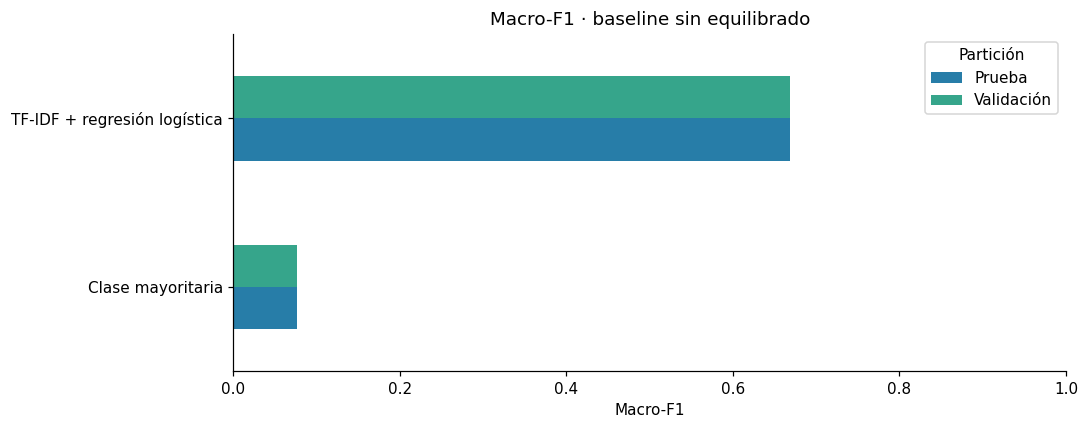

In [5]:
display(resultado["metricas"].round(4))
fig, ax = plt.subplots(figsize=(10, 4))
comparison = resultado["metricas"].pivot(index="Modelo", columns="Partición", values="Macro-F1")
comparison.plot.barh(ax=ax, color=["#277da8", "#36a58b"])
ax.set(title="Macro-F1 · baseline sin equilibrado", xlabel="Macro-F1", ylabel="", xlim=(0,1))
plt.tight_layout(); plt.show()

## 6. Rendimiento por clase y matriz de confusión

,precision,recall,f1-score,support
Checking or savings account,0.7594,0.8385,0.7970,4087.0000
Credit card,0.7807,0.7797,0.7802,5702.0000
Credit reporting or other personal consumer reports,0.9394,0.9707,0.9548,63184.0000
Debt collection,0.7917,0.6710,0.7264,7459.0000
Debt or credit management,0.0000,0.0000,0.0000,172.0000
"Money transfer, virtual currency, or money service",0.7488,0.5919,0.6612,1355.0000
Mortgage,0.8610,0.8591,0.8601,1810.0000
"Payday loan, title loan, personal loan, or advance loan",0.6582,0.2963,0.4086,702.0000
Prepaid card,0.9361,0.5318,0.6782,551.0000
Student loan,0.8876,0.8400,0.8632,1269.0000


,precision,recall,f1-score,support
Checking or savings account,0.7725,0.8453,0.8073,4086.0000
Credit card,0.7798,0.7769,0.7784,5702.0000
Credit reporting or other personal consumer reports,0.9375,0.9712,0.9541,63184.0000
Debt collection,0.7923,0.6679,0.7248,7459.0000
Debt or credit management,0.0000,0.0000,0.0000,172.0000
"Money transfer, virtual currency, or money service",0.7419,0.5727,0.6464,1355.0000
Mortgage,0.8628,0.8580,0.8604,1810.0000
"Payday loan, title loan, personal loan, or advance loan",0.7041,0.2949,0.4157,702.0000
Prepaid card,0.8938,0.5499,0.6809,551.0000
Student loan,0.8869,0.8213,0.8528,1270.0000


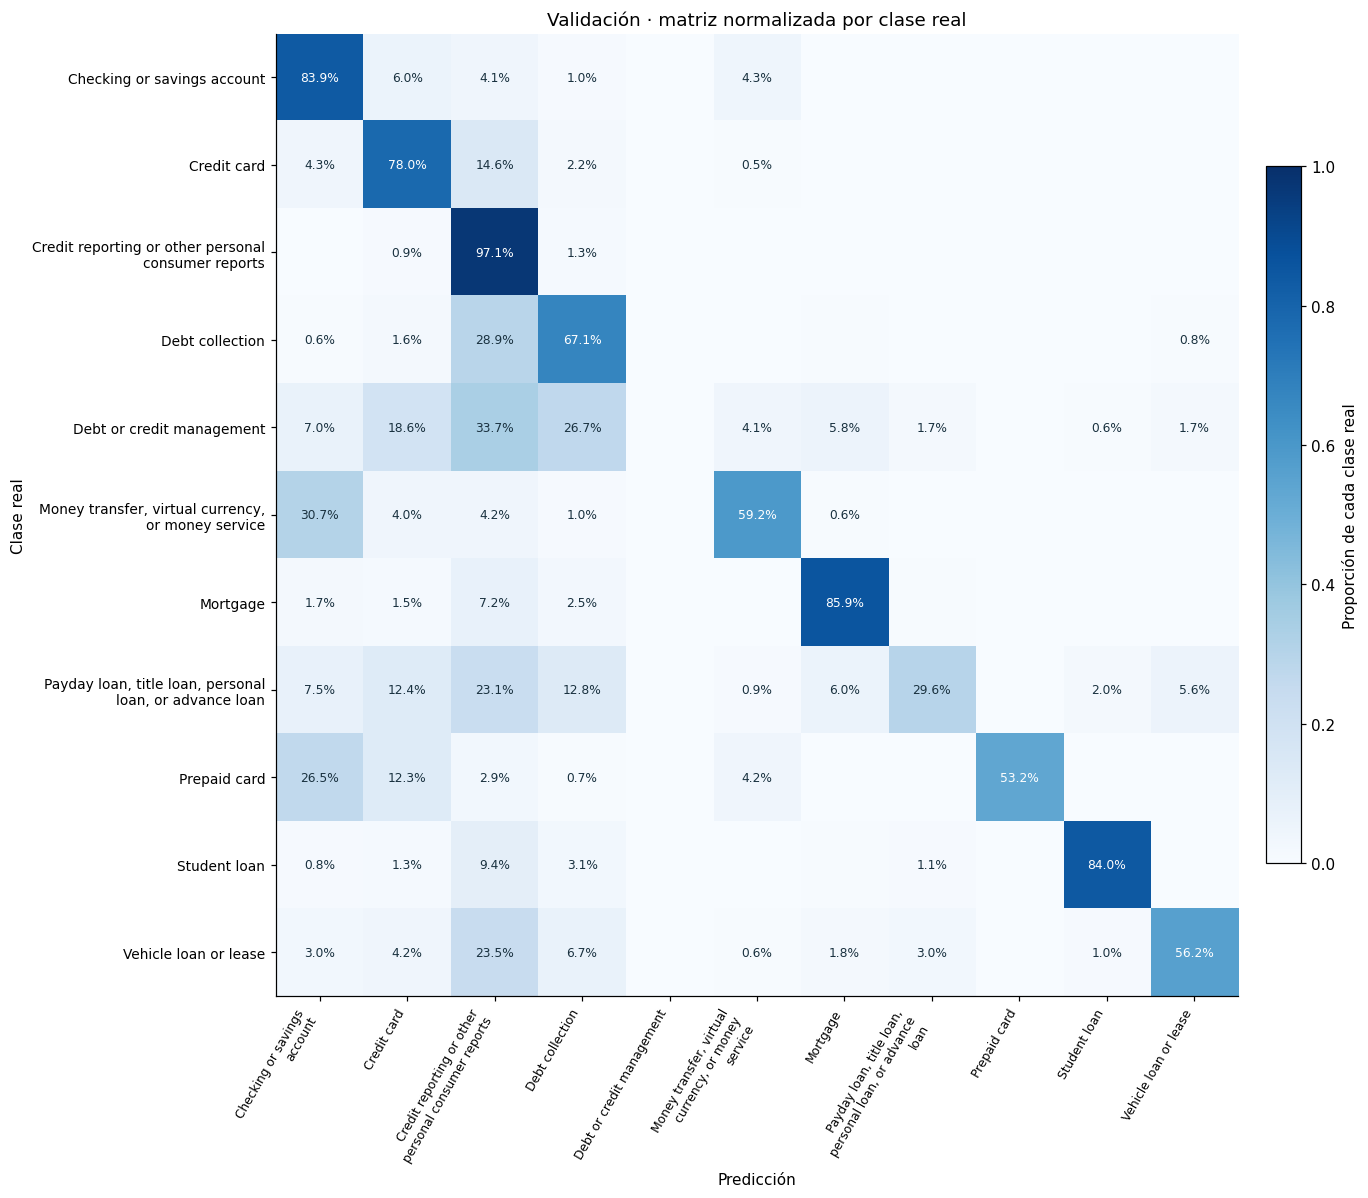

In [6]:
display(resultado["reporte_validacion"].round(4))
display(resultado["reporte_prueba"].round(4))
labels = resultado["labels"]
fig, ax = plt.subplots(figsize=(14, 11))
matrix = resultado["matriz_validacion"]
image = ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(labels)), [fill(p, 25) for p in labels], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(labels)), [fill(p, 35) for p in labels], fontsize=9)
for row in range(len(labels)):
    for col in range(len(labels)):
        if matrix[row,col] >= .005:
            ax.text(col,row,f"{matrix[row,col]:.1%}",ha="center",va="center",fontsize=8,
                    color="white" if matrix[row,col]>.5 else "#19313f")
ax.set(title="Validación · matriz normalizada por clase real", xlabel="Predicción", ylabel="Clase real")
fig.colorbar(image, ax=ax, fraction=.025, pad=.02, label="Proporción de cada clase real")
plt.tight_layout(); plt.show()

## 7. Resultados por empresa y exposición previa del texto

In [7]:
display(resultado["empresas"].round(4))

,Partición,Grupo,Filas,Accuracy,Macro-F1,F1 ponderada
0,Validación,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",20842,0.9658,0.2519,0.9657
1,Validación,"EQUIFAX, INC.",20305,0.9701,0.2884,0.9704
2,Validación,Experian Information Solutions Inc.,19599,0.9663,0.2749,0.9671
3,Validación,Resto de empresas,26628,0.7503,0.6542,0.7451
4,Prueba,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",20412,0.9649,0.2260,0.9650
5,Prueba,"EQUIFAX, INC.",20334,0.9702,0.2300,0.9704
6,Prueba,Experian Information Solutions Inc.,20011,0.9628,0.3019,0.9627
7,Prueba,Resto de empresas,26617,0.7523,0.6537,0.7469


## 8. Errores de validación

In [8]:
display(resultado["confusiones_validacion"].head(15).to_frame())

,,Errores
Real,Predicción,
Debt collection,Credit reporting or other personal consumer reports,2159
Credit reporting or other personal consumer reports,Debt collection,839
Credit card,Credit reporting or other personal consumer reports,832
Credit reporting or other personal consumer reports,Credit card,553
"Money transfer, virtual currency, or money service",Checking or savings account,416
Vehicle loan or lease,Credit reporting or other personal consumer reports,254
Checking or savings account,Credit card,246
Credit card,Checking or savings account,245
Checking or savings account,"Money transfer, virtual currency, or money service",176
